In [1]:
import hvplot.pandas

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

### ***Column Dictionary***

1. loan_amnt  
	The listed amount of the loan applied for by the borrower. If at some point in time, the credit department reduces the loan amount, then it will be reflected in this value. 

2. term  
	The number ofpayments on the loan. Values are in months and can be either 36 or 60. 

3. int_rate  
	Interest Rate on the loan. 

4. installment  
	The monthly payment owed by the Borrower if the loan originates

5. grade  
	LC assigned loan grade

6. sub_grade  
	LC assigned loan subgrade

7. emp_title  
	The job title supplied by the Borrower when applying for the loan

8. emp_length  
	Employment length in years. Possible values are between 0 and 10 where 0 means less than one year and 10 means ten or more years.

9. home_ownership  
	The home ownership status provided by the borrower during registration or obtained from the credit report. Our values are: RENT, OWN, MORTGAGE, OTHER

10. annual_inc  
	The self-reported annual income provided by the borrower during registration.

11. verification_status  
	Indicates if income was verified by LC, not verified, or if the income source was verified

12. issue_d  
	The onth which the loan was funded

13. loan_status  
	Current status of the loan

14. purpose  
	A categories provided by the Borrower for the loan request

15. title  
	The loan title provided by the Borrower

16. zip_code  
	The first 3 numbers of the zip code provided by the Borrower in the loan application

17. addr_state  
	The state provided by the Borrower in the loan application

18. dti  
	A ratio calculated using the Borrower's total monthly debt payments on the total debt obligations, excluding mortgage and the requested LC loan, divided by the Borrower's self-reported monthly income. 

19. earliest_cr_line  
	The month the borrower's earliest reported credit line was opened

20. open_acc  
	The number of open credit lines in the borrower's credit file

21. pub_rec  
	Number of derogatory public records

22. revol_bal  
	Total credit revolving balance

23. revol_util  
	Revolving line utilisation rate, or the amount of credit the Borrower is using relative to all available revolving credit

24. total_acc  
	The total number of credit lines currently in the Borrower's credit file

25. initial_list_status  
	The initial listing status of the loan. Possible values are W, F

26. application_type  
	Indicates whether the loan is an individual application or a joint application with two co-borrowers

27. mort_acc  
	Number of mortgage accounts

28. pub_rec_bankruptcies  
	Number of public record bankruptcies

### ***Data Loading & Cleaning***

In [3]:
df_accepted = pd.read_csv('acc_lending_columns_drop.csv')

df_accepted

,id,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,...,earliest_cr_line,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies
0,39651438,32000.0,60 months,10.49,687.65,B,B3,Public Service,10+ years,MORTGAGE,...,1981-10-01,20.0,0.0,39687.0,57.8,42.0,w,Individual,2.0,0.0
1,16411620,9600.0,36 months,12.99,323.42,C,C1,NaN,NaN,RENT,...,2001-04-01,13.0,1.0,4509.0,38.9,20.0,w,Individual,0.0,1.0
2,45122316,4000.0,36 months,6.68,122.93,A,A3,System Analyst,4 years,MORTGAGE,...,2003-09-01,16.0,0.0,1564.0,17.2,25.0,w,Individual,2.0,0.0
3,125356772,6025.0,36 months,10.91,197.00,B,B4,Admin assistant,10+ years,RENT,...,2005-06-01,11.0,0.0,2706.0,12.8,25.0,w,Individual,0.0,0.0
4,128490686,25000.0,60 months,26.30,752.96,E,E5,Coordinator,10+ years,OWN,...,1999-07-01,19.0,0.0,49461.0,24.7,33.0,w,Individual,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,89885744,7500.0,36 months,5.32,225.87,A,A1,Medical management,2 years,MORTGAGE,...,2003-09-01,12.0,0.0,25066.0,31.6,24.0,f,Individual,4.0,0.0
19996,134991912,6000.0,36 months,7.46,186.53,A,A4,Med tech,< 1 year,RENT,...,2013-12-01,9.0,0.0,4992.0,39.3,13.0,w,Individual,0.0,0.0
19997,115419275,11000.0,36 months,7.21,340.71,A,A3,Customer service mgr/ Logistic Mgr.,10+ years,MORTGAGE,...,1997-06-01,12.0,0.0,15038.0,58.1,23.0,w,Individual,3.0,0.0
19998,87975554,16000.0,60 months,19.99,423.82,D,D4,IT manager,5 years,OWN,...,1998-12-01,14.0,0.0,29700.0,58.0,24.0,w,Individual,0.0,0.0


In [4]:
df_accepted.shape

(20000, 29)

In [5]:
df_accepted.isnull().sum()

id                         0
loan_amnt                  0
term                       0
int_rate                   0
installment                0
grade                      0
sub_grade                  0
emp_title               1417
emp_length              1228
home_ownership             0
annual_inc                 0
verification_status        0
issue_d                    0
loan_status                0
purpose                    0
title                    192
zip_code                   0
addr_state                 0
dti                       15
earliest_cr_line           0
open_acc                   0
pub_rec                    0
revol_bal                  0
revol_util                12
total_acc                  0
initial_list_status        0
application_type           0
mort_acc                 423
pub_rec_bankruptcies      13
dtype: int64

In [6]:
df_accepted.duplicated().sum()

0

In [7]:
# show full column/dtype/non-null info and deep memory usage
df_accepted.info(verbose=True, max_cols=200, memory_usage='deep', show_counts=True)

# quick summaries
print("\nDtype counts:")
print(df_accepted.dtypes.value_counts())

print("\nTop 20 columns by missing values:")
print(df_accepted.isnull().sum().sort_values(ascending=False).head(30))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    20000 non-null  int64  
 1   loan_amnt             20000 non-null  float64
 2   term                  20000 non-null  object 
 3   int_rate              20000 non-null  float64
 4   installment           20000 non-null  float64
 5   grade                 20000 non-null  object 
 6   sub_grade             20000 non-null  object 
 7   emp_title             18583 non-null  object 
 8   emp_length            18772 non-null  object 
 9   home_ownership        20000 non-null  object 
 10  annual_inc            20000 non-null  float64
 11  verification_status   20000 non-null  object 
 12  issue_d               20000 non-null  object 
 13  loan_status           20000 non-null  object 
 14  purpose               20000 non-null  object 
 15  title              

In [8]:
# convert column issue_d from object to datetime
df_accepted['issue_d'] = pd.to_datetime(df_accepted['issue_d'], errors='coerce')
df_accepted['earliest_cr_line'] = pd.to_datetime(df_accepted['earliest_cr_line'], errors='coerce')


# Dictionary mapping state abbreviations to full names
state_dict = {
    'AL': 'Alabama', 'AK': 'Alaska', 'AZ': 'Arizona', 'AR': 'Arkansas', 'CA': 'California',
    'CO': 'Colorado', 'CT': 'Connecticut', 'DC': 'District Columbia', 'DE': 'Delaware', 'FL': 'Florida', 'GA': 'Georgia',
    'HI': 'Hawaii', 'ID': 'Idaho', 'IL': 'Illinois', 'IN': 'Indiana', 'IA': 'Iowa',
    'KS': 'Kansas', 'KY': 'Kentucky', 'LA': 'Louisiana', 'ME': 'Maine', 'MD': 'Maryland',
    'MA': 'Massachusetts', 'MI': 'Michigan', 'MN': 'Minnesota', 'MS': 'Mississippi', 'MO': 'Missouri',
    'MT': 'Montana', 'NE': 'Nebraska', 'NV': 'Nevada', 'NH': 'New Hampshire', 'NJ': 'New Jersey',
    'NM': 'New Mexico', 'NY': 'New York', 'NC': 'North Carolina', 'ND': 'North Dakota', 'OH': 'Ohio',
    'OK': 'Oklahoma', 'OR': 'Oregon', 'PA': 'Pennsylvania', 'RI': 'Rhode Island', 'SC': 'South Carolina',
    'SD': 'South Dakota', 'TN': 'Tennessee', 'TX': 'Texas', 'UT': 'Utah', 'VT': 'Vermont',
    'VA': 'Virginia', 'WA': 'Washington', 'WV': 'West Virginia', 'WI': 'Wisconsin', 'WY': 'Wyoming',
    'DC': 'District of Columbia'
}

df_accepted['addr_state'] = df_accepted['addr_state'].map(state_dict)

In [9]:
df_accepted['emp_title'] = df_accepted['emp_title'].str.replace('[^a-zA-Z0-9 ]', '', regex=True).str.lower().str.strip()
df_accepted['emp_title'] = df_accepted['emp_title'].str.replace('rn', 'registered nurse', regex=False)

In [10]:
df_accepted['verification_status'].unique()

array(['Verified', 'Not Verified', 'Source Verified'], dtype=object)

In [11]:
df_accepted['emp_title'].nunique()

df_accepted['emp_title'].value_counts().nlargest(20)

emp_title
teacher                     417
manager                     382
registered nurse            333
owner                       274
driver                      212
supervisor                  176
sales                       154
office manager              133
truck driver                117
general manager             114
project manager             109
director                    104
president                    85
vice president               78
sales manager                76
administrative assistant     76
operations manager           76
engineer                     74
police officer               73
store manager                67
Name: count, dtype: int64

In [12]:
df_accepted.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   id                    20000 non-null  int64         
 1   loan_amnt             20000 non-null  float64       
 2   term                  20000 non-null  object        
 3   int_rate              20000 non-null  float64       
 4   installment           20000 non-null  float64       
 5   grade                 20000 non-null  object        
 6   sub_grade             20000 non-null  object        
 7   emp_title             18583 non-null  object        
 8   emp_length            18772 non-null  object        
 9   home_ownership        20000 non-null  object        
 10  annual_inc            20000 non-null  float64       
 11  verification_status   20000 non-null  object        
 12  issue_d               20000 non-null  datetime64[ns]
 13  loan_status     

### ***EDA***

In [13]:
df_accepted.describe()

,id,loan_amnt,int_rate,installment,annual_inc,issue_d,dti,earliest_cr_line,open_acc,pub_rec,revol_bal,revol_util,total_acc,mort_acc,pub_rec_bankruptcies
count,2.000000e+04,20000.000000,20000.000000,20000.000000,2.000000e+04,20000,19985.000000,20000,20000.000000,20000.000000,2.000000e+04,19988.000000,20000.000000,19577.000000,19987.000000
mean,8.038813e+07,14981.621250,13.086286,443.272633,7.736764e+04,2016-05-02 17:39:37.440000256,18.861111,1999-12-16 20:53:13.920000,11.637550,0.195700,1.644481e+04,50.479218,24.057650,1.533943,0.129084
min,1.131940e+05,1000.000000,5.310000,23.010000,0.000000e+00,2007-08-01 00:00:00,0.000000,1955-04-01 00:00:00,1.000000,0.000000,0.000000e+00,0.000000,2.000000,0.000000,0.000000
25%,4.530221e+07,8000.000000,9.490000,250.290000,4.600000e+04,2015-04-01 00:00:00,11.810000,1995-12-01 00:00:00,8.000000,0.000000,5.974500e+03,31.800000,15.000000,0.000000,0.000000
50%,8.480010e+07,12800.000000,12.620000,377.370000,6.500000e+04,2016-07-01 00:00:00,17.840000,2001-06-01 00:00:00,11.000000,0.000000,1.142600e+04,50.500000,22.000000,1.000000,0.000000
75%,1.229224e+08,20000.000000,15.990000,585.232500,9.243100e+04,2017-11-01 00:00:00,24.480000,2005-04-01 00:00:00,14.000000,0.000000,2.020125e+04,69.500000,31.000000,2.000000,0.000000
max,1.456312e+08,40000.000000,30.990000,1714.540000,3.200000e+06,2018-12-01 00:00:00,999.000000,2015-10-01 00:00:00,57.000000,11.000000,1.470945e+06,128.600000,104.000000,24.000000,6.000000
std,4.504218e+07,9168.817804,4.866701,265.196291,6.306722e+04,NaN,16.207094,NaN,5.672653,0.535552,2.335642e+04,24.647872,11.897449,1.894674,0.362271


In [14]:
df_accepted['loan_status'].value_counts().hvplot.bar(
    title="Loan Status Counts", xlabel='Loan Status', ylabel='Count', 
    width=1500, height=750
)

:Bars   [loan_status]   (count)

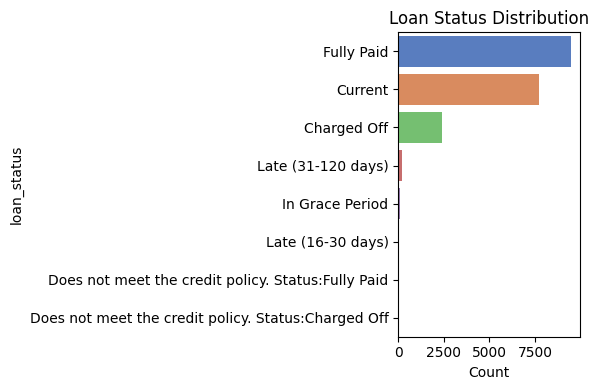

In [13]:
plt.figure(figsize=(6,4))
sns.countplot(y='loan_status', data=df_accepted, order=df_accepted['loan_status'].value_counts().index, palette='muted')
plt.title("Loan Status Distribution")
plt.xlabel("Count")
plt.tight_layout()
plt.show()

Shape: (20000, 29)

Columns and dtypes:


id                               int64
loan_amnt                      float64
term                            object
int_rate                       float64
installment                    float64
grade                           object
sub_grade                       object
emp_title                       object
emp_length                      object
home_ownership                  object
annual_inc                     float64
verification_status             object
issue_d                 datetime64[ns]
loan_status                     object
purpose                         object
title                           object
zip_code                        object
addr_state                      object
dti                            float64
earliest_cr_line        datetime64[ns]
open_acc                       float64
pub_rec                        float64
revol_bal                      float64
revol_util                     float64
total_acc                      float64
initial_list_status      


First 5 rows:


,id,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,...,earliest_cr_line,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies
0,39651438,32000.0,60 months,10.49,687.65,B,B3,public service,10+ years,MORTGAGE,...,1981-10-01,20.0,0.0,39687.0,57.8,42.0,w,Individual,2.0,0.0
1,16411620,9600.0,36 months,12.99,323.42,C,C1,NaN,NaN,RENT,...,2001-04-01,13.0,1.0,4509.0,38.9,20.0,w,Individual,0.0,1.0
2,45122316,4000.0,36 months,6.68,122.93,A,A3,system analyst,4 years,MORTGAGE,...,2003-09-01,16.0,0.0,1564.0,17.2,25.0,w,Individual,2.0,0.0
3,125356772,6025.0,36 months,10.91,197.00,B,B4,admin assistant,10+ years,RENT,...,2005-06-01,11.0,0.0,2706.0,12.8,25.0,w,Individual,0.0,0.0
4,128490686,25000.0,60 months,26.30,752.96,E,E5,coordinator,10+ years,OWN,...,1999-07-01,19.0,0.0,49461.0,24.7,33.0,w,Individual,0.0,0.0



Descriptive statistics (numeric):


,count,mean,min,25%,50%,75%,max,std
id,20000.0,80388133.9889,113194.0,45302212.0,84800096.5,122922448.25,145631160.0,45042179.130651
loan_amnt,20000.0,14981.62125,1000.0,8000.0,12800.0,20000.0,40000.0,9168.817804
int_rate,20000.0,13.086286,5.31,9.49,12.62,15.99,30.99,4.866701
installment,20000.0,443.272633,23.01,250.29,377.37,585.2325,1714.54,265.196291
annual_inc,20000.0,77367.636013,0.0,46000.0,65000.0,92431.0,3200000.0,63067.223659
issue_d,20000,2016-05-02 17:39:37.440000256,2007-08-01 00:00:00,2015-04-01 00:00:00,2016-07-01 00:00:00,2017-11-01 00:00:00,2018-12-01 00:00:00,NaN
dti,19985.0,18.861111,0.0,11.81,17.84,24.48,999.0,16.207094
earliest_cr_line,20000,1999-12-16 20:53:13.920000,1955-04-01 00:00:00,1995-12-01 00:00:00,2001-06-01 00:00:00,2005-04-01 00:00:00,2015-10-01 00:00:00,NaN
open_acc,20000.0,11.63755,1.0,8.0,11.0,14.0,57.0,5.672653
pub_rec,20000.0,0.1957,0.0,0.0,0.0,0.0,11.0,0.535552



Missing values (count and %):


,0,percent
emp_title,1417,7.085
emp_length,1228,6.140
title,192,0.960
dti,15,0.075
revol_util,12,0.060
mort_acc,423,2.115
pub_rec_bankruptcies,13,0.065



Duplicate rows: 0

Categorical columns: ['term', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'verification_status', 'loan_status', 'purpose', 'title', 'zip_code', 'addr_state', 'initial_list_status', 'application_type']


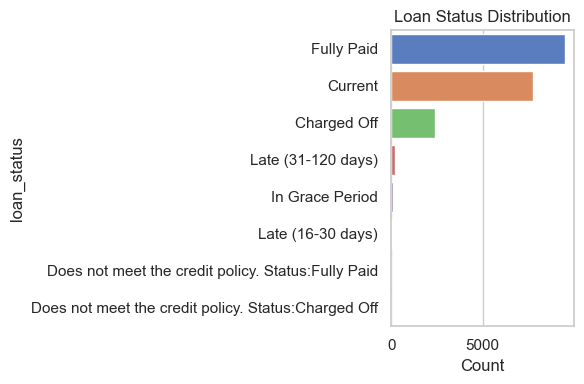

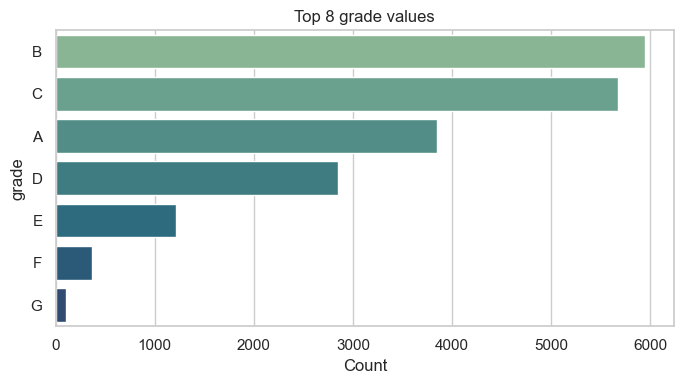

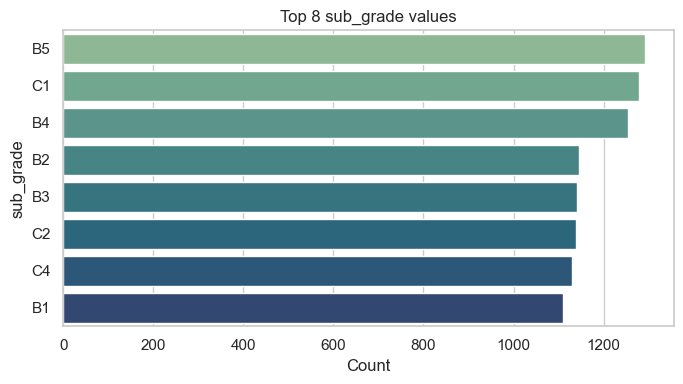

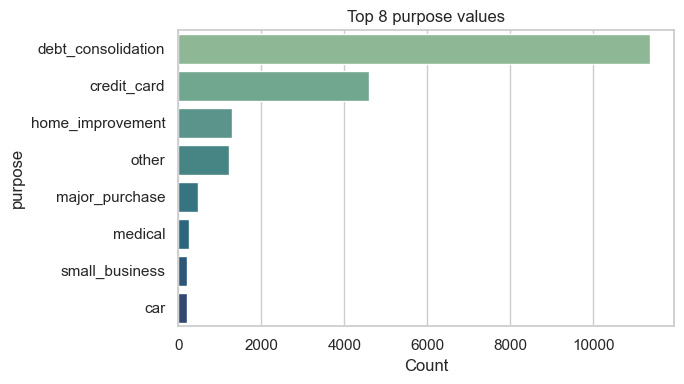

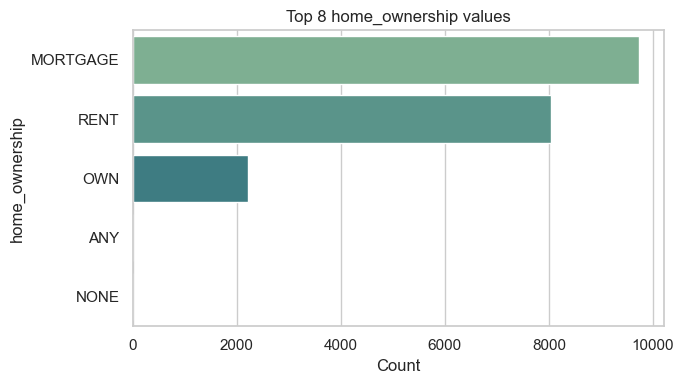

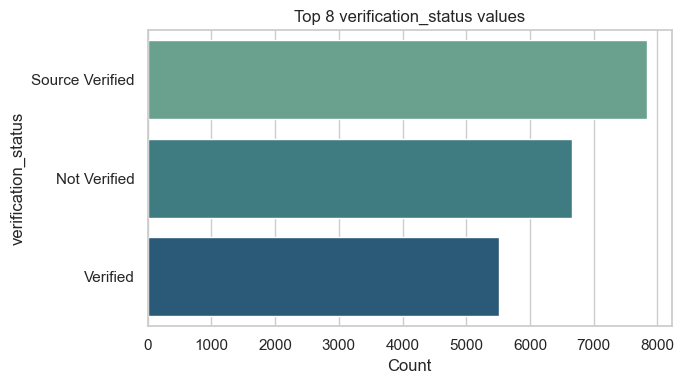

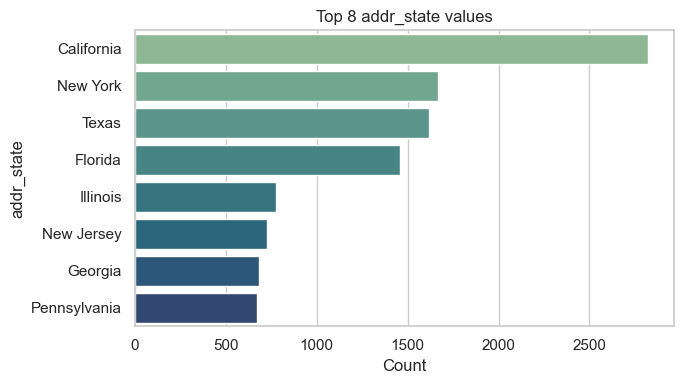

<Figure size 1200x800 with 0 Axes>

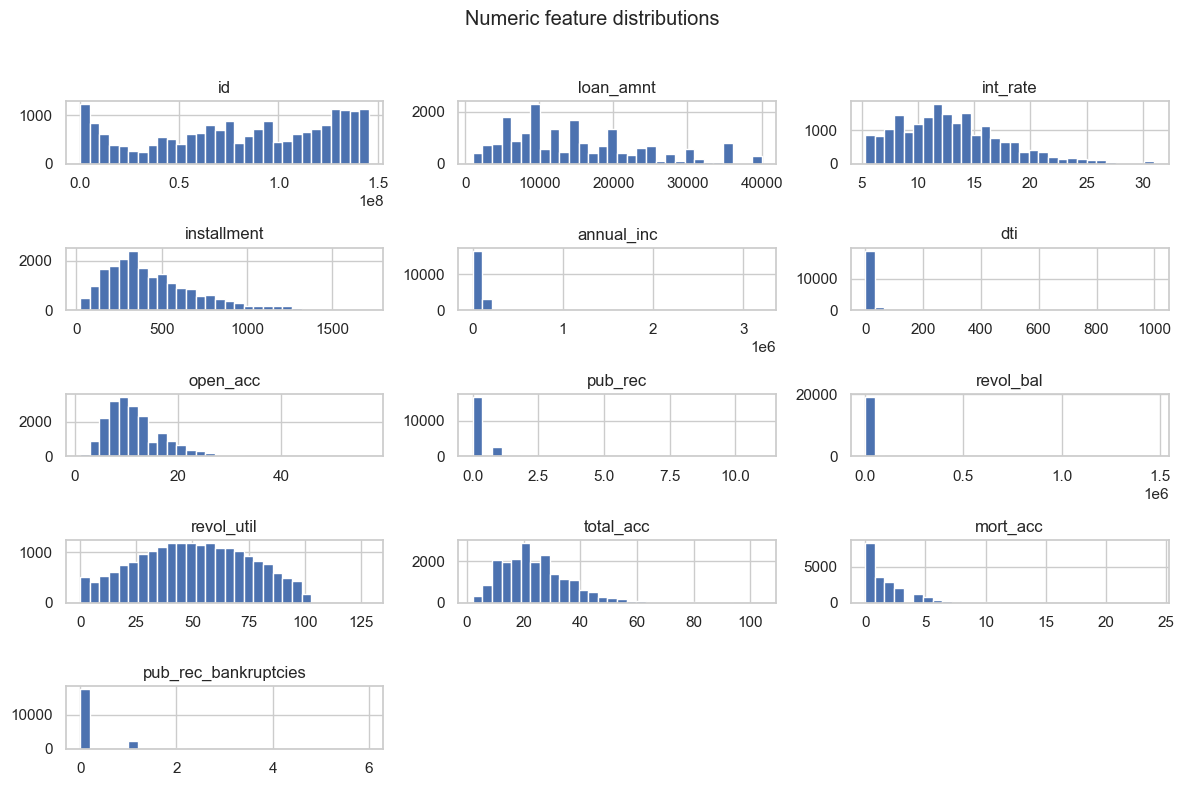

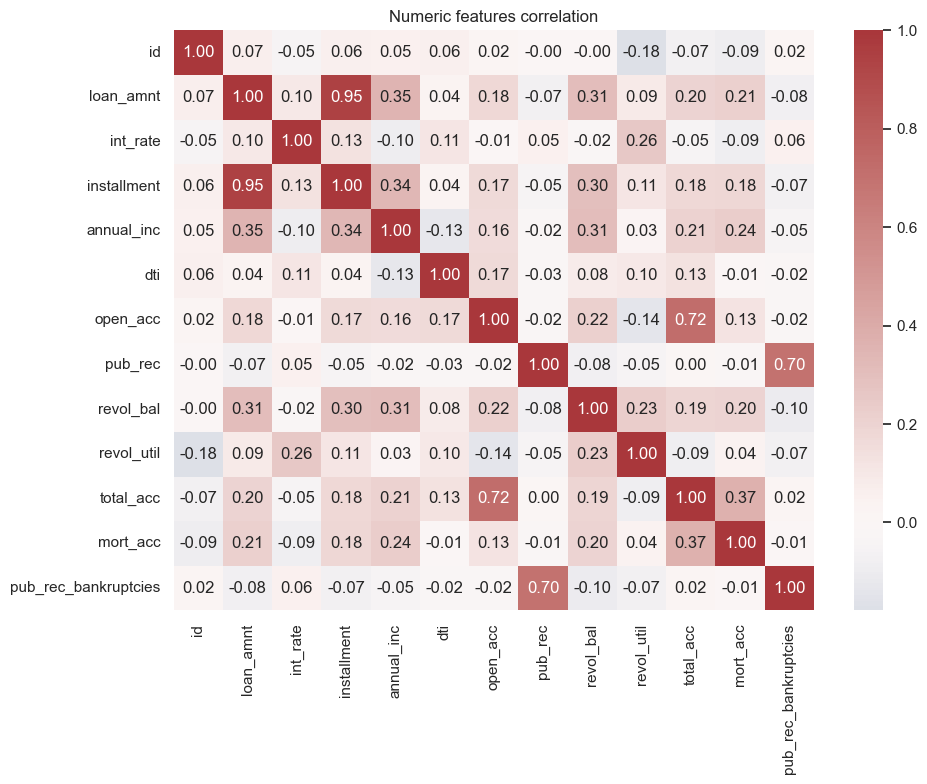

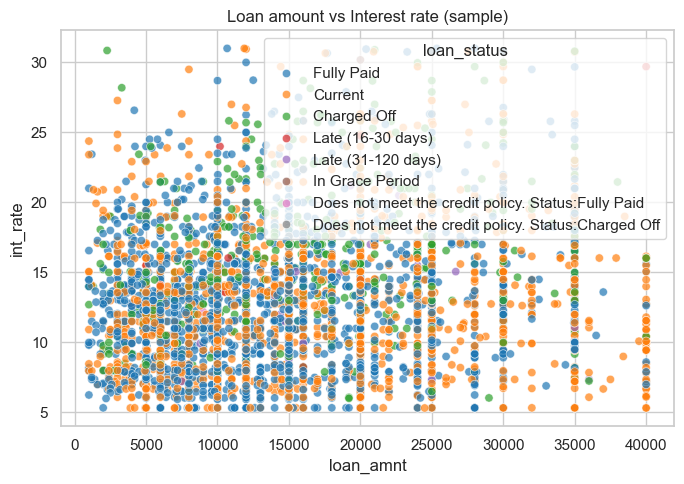

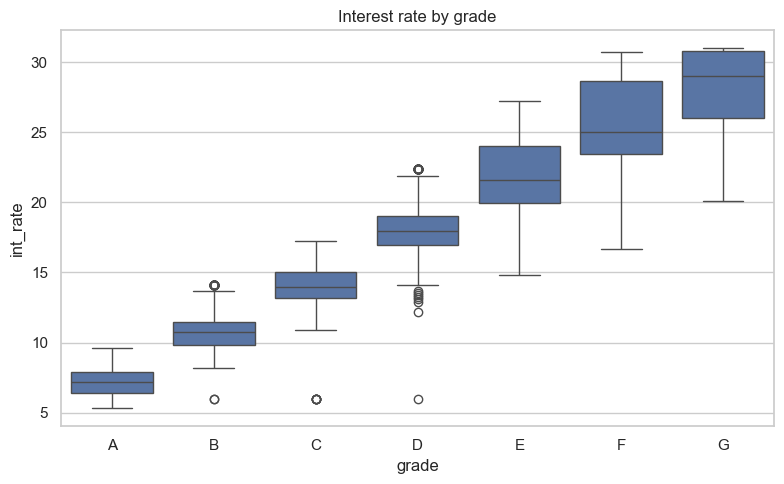

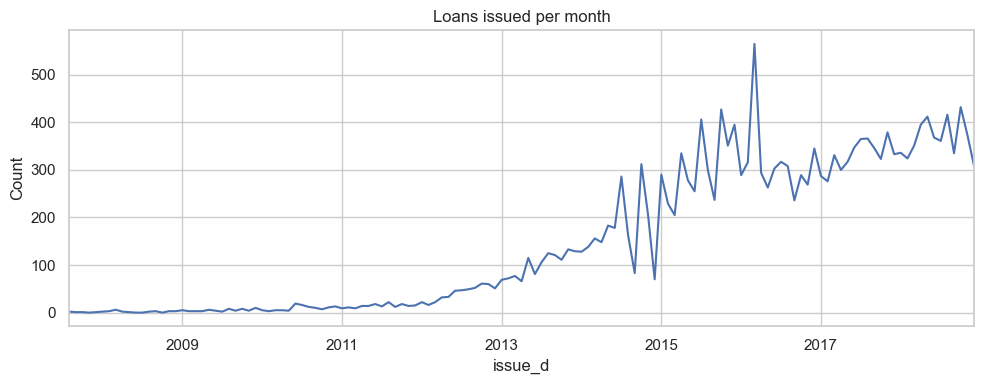


Interest rate by grade:


,mean,median,count
grade,,,
A,7.081636,7.21,3852
B,10.676084,10.75,5942
C,14.149543,13.99,5673
D,18.157745,17.99,2847
E,21.964350,21.60,1216
F,25.572617,24.99,363
G,28.532804,28.99,107



Top purposes by loan amount/count:


,mean,median,count
purpose,,,
debt_consolidation,15910.453827,14700.0,11381
credit_card,15245.464457,13000.0,4586
home_improvement,14458.217324,12000.0,1293
other,10153.378378,7250.0,1221
major_purchase,12255.591398,9350.0,465
medical,9890.100000,7462.5,250
small_business,16577.023810,15000.0,210
car,9664.467005,7000.0,197
vacation,6102.906977,5000.0,129


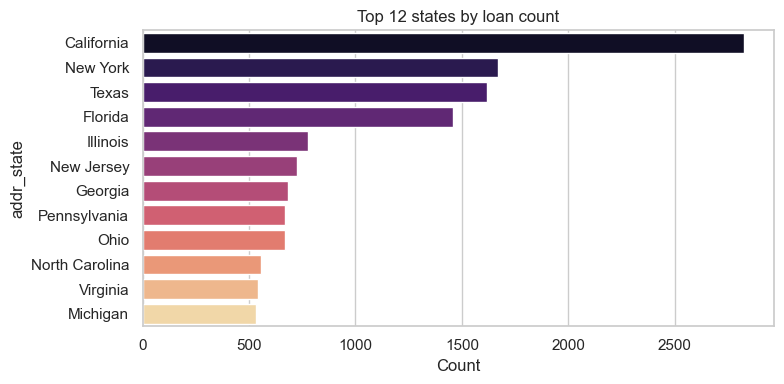


EDA completed.


In [14]:
# EDA helper cell for df_accepted
# Assumes pandas, numpy, seaborn, matplotlib, hvplot.pandas are already imported
# and df_accepted & state_dict exist in the notebook environment.

def run_eda(df):
    warnings.filterwarnings("ignore")
    sns.set(style="whitegrid")
    
    print("Shape:", df.shape)
    print("\nColumns and dtypes:")
    display(df.dtypes)
    
    print("\nFirst 5 rows:")
    display(df.head())
    
    print("\nDescriptive statistics (numeric):")
    display(df.describe().T)
    
    # Missing values
    missing = df.isnull().sum()
    missing_pct = (missing / len(df) * 100).sort_values(ascending=False)
    print("\nMissing values (count and %):")
    display(pd.concat([missing, missing_pct.rename("percent")], axis=1).loc[lambda x: x["percent"]>0])
    
    # Duplicates
    print("\nDuplicate rows:", df.duplicated().sum())
    
    # Categorical overview
    cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
    print("\nCategorical columns:", cat_cols)
    
    # Target distribution
    if 'loan_status' in df.columns:
        plt.figure(figsize=(6,4))
        sns.countplot(y='loan_status', data=df, order=df['loan_status'].value_counts().index, palette='muted')
        plt.title("Loan Status Distribution")
        plt.xlabel("Count")
        plt.tight_layout()
        plt.show()
    
    # Top categorical counts (top 8) as horizontal bar charts
    def plot_top(col, top=8):
        plt.figure(figsize=(7,4))
        order = df[col].value_counts().nlargest(top).index
        sns.countplot(y=col, data=df, order=order, palette='crest')
        plt.title(f"Top {top} {col} values")
        plt.xlabel("Count")
        plt.tight_layout()
        plt.show()
    
    to_plot = ['grade', 'sub_grade', 'purpose', 'home_ownership', 'verification_status', 'addr_state']
    for c in to_plot:
        if c in df.columns:
            plot_top(c, top=8)
    
    # Numeric distributions
    num_cols = df.select_dtypes(include=['number']).columns.tolist()
    if num_cols:
        plt.figure(figsize=(12, 8))
        df[num_cols].hist(bins=30, layout=(int(len(num_cols)/3)+1, 3), figsize=(12, 8))
        plt.suptitle("Numeric feature distributions")
        plt.tight_layout(rect=[0, 0, 1, 0.96])
        plt.show()
    
    # Correlation heatmap for numeric features
    if len(num_cols) >= 2:
        corr = df[num_cols].corr()
        plt.figure(figsize=(10,8))
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0)
        plt.title("Numeric features correlation")
        plt.tight_layout()
        plt.show()
    
    # Relationship examples
    if {'loan_amnt', 'int_rate'}.issubset(df.columns):
        plt.figure(figsize=(7,5))
        sns.scatterplot(x='loan_amnt', y='int_rate', hue='loan_status' if 'loan_status' in df.columns else None,
                        data=df.sample(frac=0.2, random_state=1), alpha=0.7, palette='tab10')
        plt.title("Loan amount vs Interest rate (sample)")
        plt.tight_layout()
        plt.show()
    
    if {'int_rate', 'grade'}.issubset(df.columns):
        plt.figure(figsize=(8,5))
        sns.boxplot(x='grade', y='int_rate', data=df, order=sorted(df['grade'].unique()))
        plt.title("Interest rate by grade")
        plt.tight_layout()
        plt.show()
    
    # Time series: loans issued over time (monthly)
    if 'issue_d' in df.columns:
        issue_ts = df.set_index('issue_d').resample('M').size()
        plt.figure(figsize=(10,4))
        issue_ts.plot()
        plt.title("Loans issued per month")
        plt.ylabel("Count")
        plt.tight_layout()
        plt.show()
    
    # Aggregations: average interest rate and loan amount by grade/purpose/state
    aggs = {}
    if 'int_rate' in df.columns and 'grade' in df.columns:
        aggs['int_by_grade'] = df.groupby('grade')['int_rate'].agg(['mean','median','count']).sort_index()
        print("\nInterest rate by grade:")
        display(aggs['int_by_grade'])
    if 'loan_amnt' in df.columns and 'purpose' in df.columns:
        aggs['loan_by_purpose'] = df.groupby('purpose')['loan_amnt'].agg(['mean','median','count']).sort_values('count', ascending=False).head(10)
        print("\nTop purposes by loan amount/count:")
        display(aggs['loan_by_purpose'])
    if 'addr_state' in df.columns:
        state_counts = df['addr_state'].value_counts().head(12)
        plt.figure(figsize=(8,4))
        sns.barplot(x=state_counts.values, y=state_counts.index, palette='magma')
        plt.title("Top 12 states by loan count")
        plt.xlabel("Count")
        plt.tight_layout()
        plt.show()
    
    print("\nEDA completed.")

# Run EDA on df_accepted
run_eda(df_accepted)

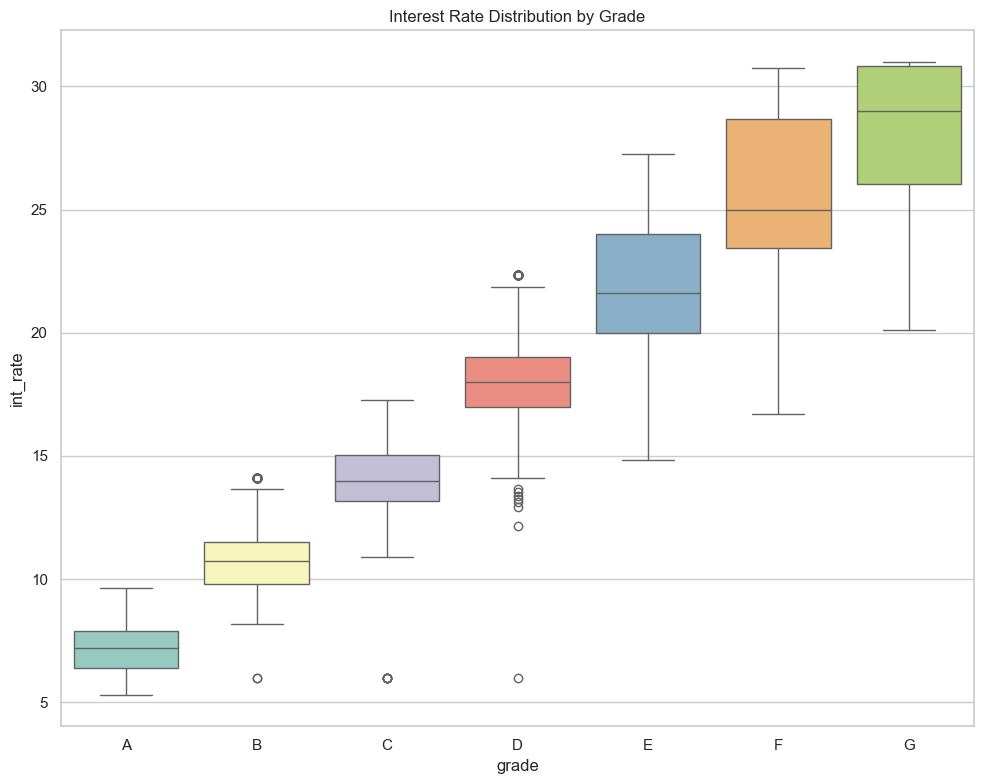

In [15]:
plt.figure(figsize=(10,8))
sns.boxplot(x='grade', y='int_rate', data=df_accepted,
             order=sorted(df_accepted['grade'].unique()), palette='Set3')
plt.title("Interest Rate Distribution by Grade")
plt.tight_layout()
plt.show()

In [16]:
df_accepted['loan_status'].unique()

array(['Current', 'Fully Paid', 'Charged Off', 'Late (31-120 days)',
       'Late (16-30 days)', 'In Grace Period',
       'Does not meet the credit policy. Status:Fully Paid',
       'Does not meet the credit policy. Status:Charged Off'],
      dtype=object)

In [18]:
# Missing Values handling 
categoric = []
numeric = []

categoric_columns = df_accepted.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_columns = df_accepted.select_dtypes(include=['number']).columns.tolist()

for i in categoric_columns:
    categoric = df_accepted[i].isnull().sum()
    if categoric > 0:
        df_accepted[i].fillna(df_accepted[i].mode()[0], inplace=True)

for j in numeric_columns:
    numeric = df_accepted[j].isnull().sum()
    if numeric > 0:
        df_accepted[j].fillna(df_accepted[j].median(), inplace=True)


df_accepted.isnull().sum()

id                      0
loan_amnt               0
term                    0
int_rate                0
installment             0
grade                   0
sub_grade               0
emp_title               0
emp_length              0
home_ownership          0
annual_inc              0
verification_status     0
issue_d                 0
loan_status             0
purpose                 0
title                   0
zip_code                0
addr_state              0
dti                     0
earliest_cr_line        0
open_acc                0
pub_rec                 0
revol_bal               0
revol_util              0
total_acc               0
initial_list_status     0
application_type        0
mort_acc                0
pub_rec_bankruptcies    0
dtype: int64

In [17]:
df_accepted['emp_length'].unique()

array(['10+ years', nan, '4 years', '5 years', '8 years', '7 years',
       '2 years', '1 year', '< 1 year', '9 years', '6 years', '3 years'],
      dtype=object)

In [18]:
numeric_columns = df_accepted.select_dtypes(include=['number']).columns.tolist()

misval_numeric_columns = []
normal = []
skew = []
extreme_skew = []

for col in numeric_columns:
    misval_count = df_accepted[col].isnull().sum()
    if misval_count > 0:
        misval_numeric_columns.append((col, misval_count))

for mis_col in numeric_columns:
    skewness = df_accepted[mis_col].skew()
    if abs(skewness) < 0.5:
        normal.append(mis_col)
    elif 0.5 <= abs(skewness) < 1:
        skew.append(mis_col)
    else:
        extreme_skew.append(mis_col)

print("Numeric columns with missing values and their counts:", misval_numeric_columns)
print("Normal distribution columns:", normal)
print("Skewed distribution columns:", skew)
print("Extremely skewed distribution columns:", extreme_skew)

Numeric columns with missing values and their counts: [('dti', 15), ('revol_util', 12), ('mort_acc', 423), ('pub_rec_bankruptcies', 13)]
Normal distribution columns: ['id', 'revol_util']
Skewed distribution columns: ['loan_amnt', 'int_rate', 'total_acc']
Extremely skewed distribution columns: ['installment', 'annual_inc', 'dti', 'open_acc', 'pub_rec', 'revol_bal', 'mort_acc', 'pub_rec_bankruptcies']


In [19]:
df_save = df_accepted.copy()

df_save.to_csv('acc_lending.csv', index=False)

### ***Feature Engine***